# Video 7: Unsupervised clustering

Notes for this notebook.

This notebook generates the visuals for the seventh video in the Multimodal Spatial Biology series. So far, we have looked at cell types one marker at a time, with a threshold we chose ourselves. Here we let all sixteen COMET protein markers together define cell populations, using unsupervised clustering, and see what emerges without telling the algorithm what to look for in advance.

We compare two clustering approaches, K-means and Leiden, since they behave quite differently on this kind of data, and being upfront about that difference is itself part of the lesson.

This notebook reuses the quantification table from Video 3. All output images are saved into outputs/video7.

This notebook needs two extra packages beyond what earlier videos used, scanpy and leidenalg, for the Leiden clustering step. Install them with pip install scanpy python-igraph leidenalg if you have not already.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video7")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video7


## Load the table and prepare the markers

We reuse the same per cell table from Video 3. For clustering, we use all sixteen COMET protein columns except DAPI. DAPI is a general nuclear stain, not a cell type marker, including it would group cells by nuclear brightness rather than identity.

We standardize every marker, subtracting the mean and dividing by the standard deviation, so that markers with naturally higher raw intensity do not dominate the clustering just because of their scale.


In [3]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("outputs/video3/core01_hcc_quantification.csv")
print("Table shape:", df.shape)

marker_cols = [c for c in df.columns if c.endswith("_mean") and c != "DAPI_mean"]
print("Using markers:", marker_cols)

X = StandardScaler().fit_transform(df[marker_cols].values)


Table shape: (8283, 5022)
Using markers: ['CK8 - TRITC_mean', 'VEGF - TRITC_mean', 'CD45RA - TRITC_mean', 'vimentin - TRITC_mean', 'E-Cadherin - TRITC_mean', 'CD1c - TRITC_mean', 'IL-10 - TRITC_mean', 'podoplanin - FITC_mean', 'FXIIIa - FITC_mean', 'CD66 - FITC_mean', 'CD20 - TRITC_mean', 'αSMA - TRITC_mean', 'CD45 - TRITC_mean', 'HepPar1 - TRITC_mean', 'CD206 - TRITC_mean']


## First attempt, K-means

K-means is the simpler, faster method, but it requires us to decide the number of clusters in advance. We sweep a range of values and use the silhouette score, a measure of how well separated the resulting clusters are, to pick the best one.


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("K-means silhouette scores by k:")
best_k, best_score = None, -1
for k in range(3, 9):
    labels = KMeans(n_clusters=k, random_state=0, n_init=10).fit_predict(X)
    score = silhouette_score(X, labels)
    print(f"k={k}: silhouette = {score:.3f}")
    if score > best_score:
        best_k, best_score = k, score

print(f"\nBest k by silhouette: {best_k}")

kmeans_labels = KMeans(n_clusters=best_k, random_state=0, n_init=10).fit_predict(X)
df["kmeans_cluster"] = kmeans_labels


K-means silhouette scores by k:
k=3: silhouette = 0.272
k=4: silhouette = 0.222
k=5: silhouette = 0.241
k=6: silhouette = 0.249
k=7: silhouette = 0.214
k=8: silhouette = 0.227

Best k by silhouette: 3


## Are these clusters actually real cell types

A silhouette score tells us the clusters are mathematically well separated, it does not tell us whether they correspond to real biology. Let us look at what defines each cluster, and check cell size and DAPI intensity as a sanity check, since a cluster defined mainly by dim, weak staining across the board is more likely a technical artifact than a real cell population.


In [5]:
cluster_profile = df.groupby("kmeans_cluster")[marker_cols].mean()
cluster_profile_z = ((cluster_profile - cluster_profile.mean()) / cluster_profile.std()).round(2)

print("Top 3 defining markers per K-means cluster:")
for cluster_id in cluster_profile_z.index:
    top_markers = cluster_profile_z.loc[cluster_id].sort_values(ascending=False).head(3)
    print(f"Cluster {cluster_id}: {list(top_markers.index)}")

print(f"\nCluster sizes: {df['kmeans_cluster'].value_counts().to_dict()}")

print("\nMean cell area and DAPI intensity per cluster, a sanity check against dim cell artifacts:")
print(df.groupby("kmeans_cluster")[["area_px", "DAPI_mean"]].mean())


Top 3 defining markers per K-means cluster:
Cluster 0: ['E-Cadherin - TRITC_mean', 'IL-10 - TRITC_mean', 'CK8 - TRITC_mean']
Cluster 1: ['vimentin - TRITC_mean', 'VEGF - TRITC_mean', 'CK8 - TRITC_mean']
Cluster 2: ['CD45RA - TRITC_mean', 'FXIIIa - FITC_mean', 'αSMA - TRITC_mean']

Cluster sizes: {0: 3601, 1: 2777, 2: 1905}

Mean cell area and DAPI intensity per cluster, a sanity check against dim cell artifacts:
                    area_px   DAPI_mean
kmeans_cluster                         
0               1235.477552  379.589589
1                805.739743  316.352131
2                446.170647  720.084829


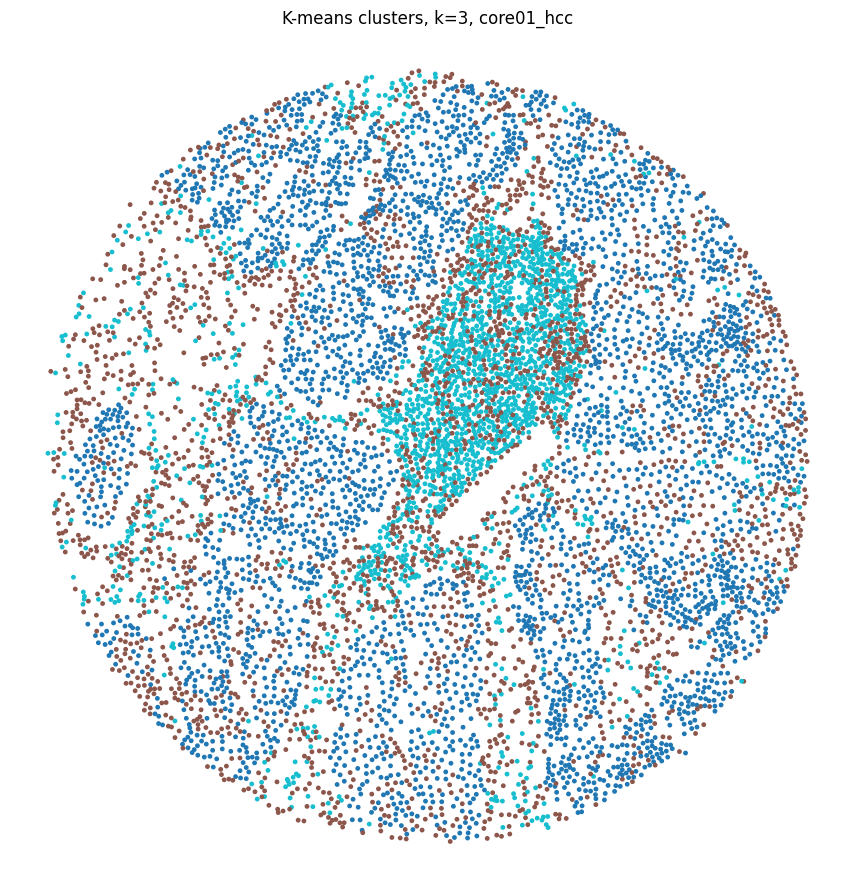

Saved slide_kmeans_clusters.png


In [6]:
fig, ax = plt.subplots(figsize=(9, 9))
sc_plot = ax.scatter(df["centroid_x"], df["centroid_y"], c=kmeans_labels, cmap="tab10", s=6)
ax.set_title(f"K-means clusters, k={best_k}, core01_hcc")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_kmeans_clusters.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_kmeans_clusters.png")


One of the three K-means clusters is defined mainly by several markers being simultaneously low, rather than by a clear positive signature, and it also shows the lowest DAPI intensity of the three. This is the kind of pattern that can arise from generally weak staining across a group of cells, rather than a shared, distinct biology. K-means, forced to produce exactly three groups from the whole marker set at once, may be blending a real population together with this kind of ambiguous, dim group.

This is a real limitation worth sitting with, rather than picking a different k and hoping it goes away. Let us try a different kind of clustering method built for exactly this situation.


## A graph based alternative, Leiden

Leiden clustering builds a graph connecting each cell to its nearest neighbors in marker space, then finds tightly connected communities within that graph. Unlike K-means, it does not need a fixed number of clusters ahead of time, though it does have a resolution setting that controls how finely it splits communities.

Let us first try the default resolution and see what happens.


In [7]:
import scanpy as sc
import anndata as ad
from sklearn.metrics import adjusted_rand_score

adata = ad.AnnData(X)
sc.pp.neighbors(adata, n_neighbors=15)
sc.tl.leiden(adata, resolution=1.0)
leiden_default_labels = adata.obs["leiden"].astype(int).values

print(f"Leiden at the default resolution found {len(set(leiden_default_labels))} clusters")

ari_default = adjusted_rand_score(kmeans_labels, leiden_default_labels)
print(f"Adjusted Rand Index against K-means: {ari_default:.3f}")


c:\Users\m6sbhatt\AppData\Local\anaconda3\envs\unumlocalia-env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\m6sbhatt\AppData\Local\Temp\ipykernel_18200\1607550824.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=1.0)


Leiden at the default resolution found 15 clusters
Adjusted Rand Index against K-means: 0.193


The default resolution produces far more clusters than K-means, and the two methods barely agree, a low Adjusted Rand Index. Fifteen clusters out of sixteen markers, several of which we already know are quite noisy, likely means Leiden is over splitting on marker noise rather than finding this many truly distinct, robust populations.

Rather than accepting either extreme, let us lower the resolution and look for a middle ground.


In [8]:
sc.tl.leiden(adata, resolution=0.3, key_added="leiden_low_res")
leiden_labels = adata.obs["leiden_low_res"].astype(int).values
df["leiden_cluster"] = leiden_labels

print(f"Leiden at resolution 0.3 found {len(set(leiden_labels))} clusters")

ari_low = adjusted_rand_score(kmeans_labels, leiden_labels)
print(f"Adjusted Rand Index against K-means: {ari_low:.3f}")

print(f"\nCluster sizes: {df['leiden_cluster'].value_counts().to_dict()}")


Leiden at resolution 0.3 found 5 clusters
Adjusted Rand Index against K-means: 0.483

Cluster sizes: {0: 2062, 1: 2043, 2: 1791, 3: 1544, 4: 843}


## What defines each of these five clusters

Let us look at the top defining markers for each of these five clusters, the same way we did for K-means.


In [9]:
cluster_profile_leiden = df.groupby("leiden_cluster")[marker_cols].mean()
cluster_profile_leiden_z = ((cluster_profile_leiden - cluster_profile_leiden.mean()) / cluster_profile_leiden.std()).round(2)

print("Top 3 defining markers per Leiden cluster:")
for cluster_id in cluster_profile_leiden_z.index:
    top_markers = cluster_profile_leiden_z.loc[cluster_id].sort_values(ascending=False).head(3)
    print(f"Cluster {cluster_id}: {list(top_markers.index)}")


Top 3 defining markers per Leiden cluster:
Cluster 0: ['IL-10 - TRITC_mean', 'CK8 - TRITC_mean', 'VEGF - TRITC_mean']
Cluster 1: ['CD45RA - TRITC_mean', 'CD45 - TRITC_mean', 'FXIIIa - FITC_mean']
Cluster 2: ['vimentin - TRITC_mean', 'VEGF - TRITC_mean', 'αSMA - TRITC_mean']
Cluster 3: ['CK8 - TRITC_mean', 'IL-10 - TRITC_mean', 'E-Cadherin - TRITC_mean']
Cluster 4: ['podoplanin - FITC_mean', 'E-Cadherin - TRITC_mean', 'CD66 - FITC_mean']


## Confirming the known immune population numerically

We already know, from earlier videos, roughly where the immune aggregate sits and what CD45 protein levels look like there. Rather than reading cluster identity off a color in a plot, let us check numerically what fraction of each cluster would count as CD45 high, using the same threshold from Video 5.


In [10]:
threshold = 515.1  # same CD45 threshold used in Video 5

df["cd45_high"] = df["CD45 - TRITC_mean"] > threshold
overlap = (df.groupby("leiden_cluster")["cd45_high"].mean() * 100).round(1)
print("Percent of CD45 high cells in each Leiden cluster:")
print(overlap)


Percent of CD45 high cells in each Leiden cluster:
leiden_cluster
0     0.1
1    45.2
2     3.3
3     0.1
4     1.1
Name: cd45_high, dtype: float64


One cluster stands out sharply, with close to half of its cells counting as CD45 high, while every other cluster sits under five percent. This confirms, numerically rather than by eye, that Leiden found the same immune population we identified earlier in the series through direct thresholding, purely from letting all sixteen markers cluster together.


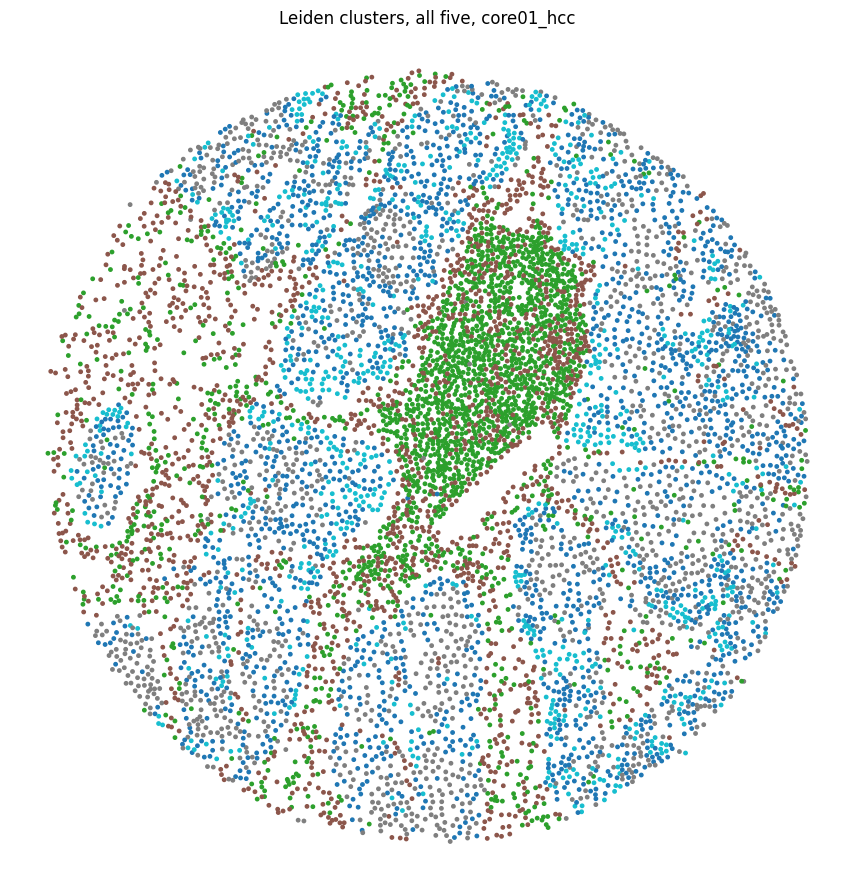

Saved slide_leiden_all_clusters.png


In [11]:
fig, ax = plt.subplots(figsize=(9, 9))
sc_plot = ax.scatter(df["centroid_x"], df["centroid_y"], c=leiden_labels, cmap="tab10", s=6)
ax.set_title("Leiden clusters, all five, core01_hcc")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_leiden_all_clusters.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_leiden_all_clusters.png")


## Looking at each cluster on its own

Five overlapping colors on one plot can be hard to read. Let us look at each cluster in isolation, on its own panel, to judge whether it shows real spatial structure or looks like random scatter.


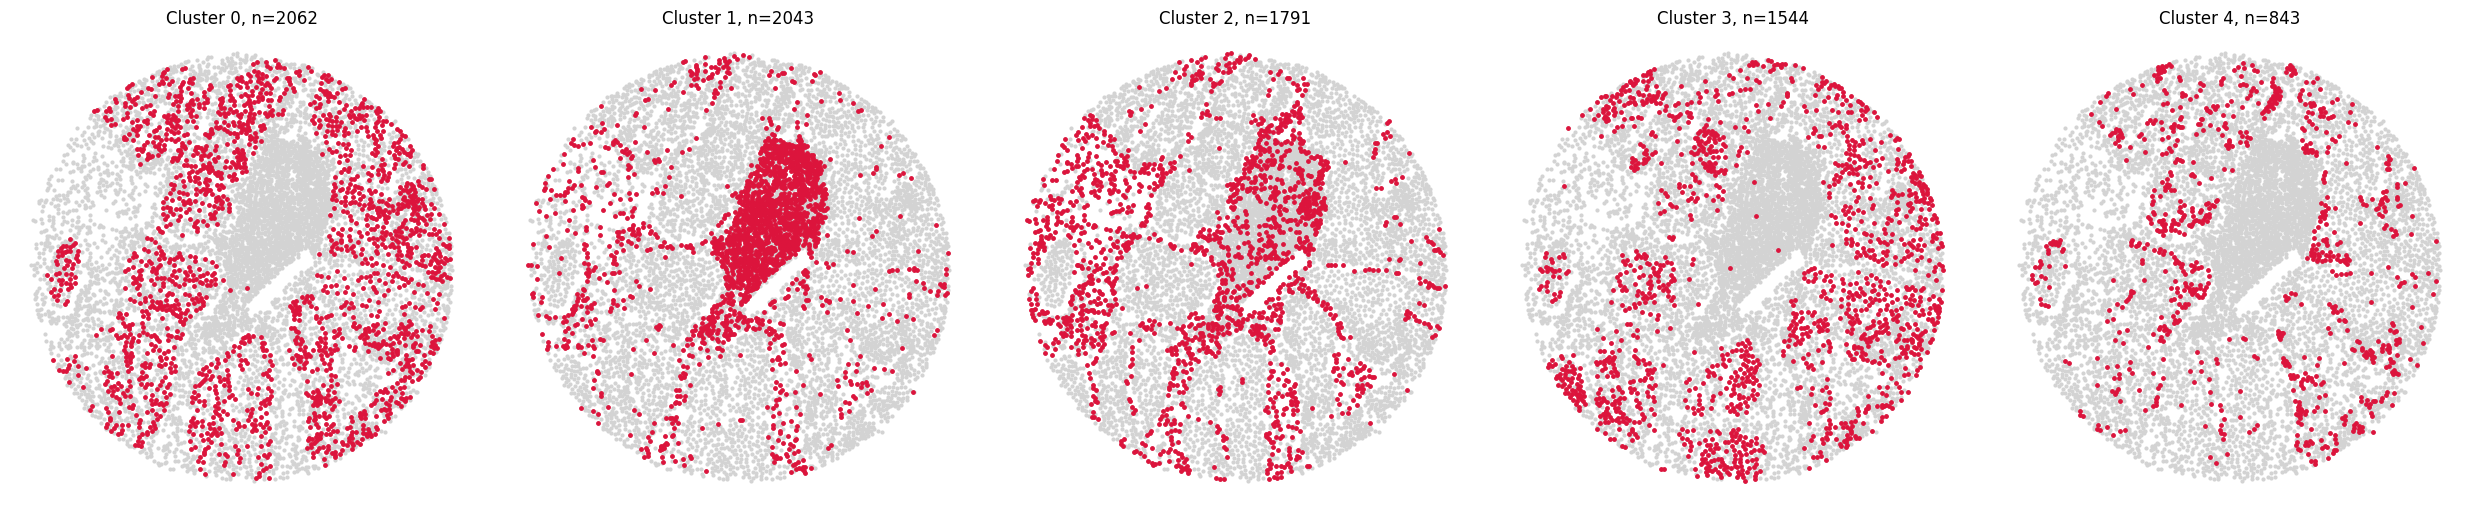

Saved slide_leiden_clusters_isolated.png


In [12]:
n_clusters = len(sorted(df["leiden_cluster"].unique()))
fig, axes = plt.subplots(1, n_clusters, figsize=(5 * n_clusters, 5))

for cluster_id in sorted(df["leiden_cluster"].unique()):
    ax = axes[cluster_id]
    mask = df["leiden_cluster"] == cluster_id
    ax.scatter(df["centroid_x"], df["centroid_y"], c="lightgray", s=4)
    ax.scatter(df.loc[mask, "centroid_x"], df.loc[mask, "centroid_y"], c="crimson", s=6)
    ax.set_title(f"Cluster {cluster_id}, n={mask.sum()}")
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_leiden_clusters_isolated.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_leiden_clusters_isolated.png")


## Reading the five populations

Each of these five clusters shows real, non random spatial organization, which is itself evidence they correspond to genuine biology rather than noise.

The confirmed immune cluster occupies the same aggregate we have referenced throughout this series. A second cluster, defined by vimentin, VEGF, and alpha SMA, traces thin branching lines between tumor nodules rather than filling solid regions, consistent with stromal and vascular tissue running through the connective septa, the same structures visible in the H and E image from this core. Two further clusters both show epithelial marker profiles, cytokeratin and E-Cadherin dominant, but occupy different, largely separate nodules, which may reflect real heterogeneity between tumor regions rather than one uniform tumor cell population.

The smallest cluster, only a few hundred cells, is defined by podoplanin, E-Cadherin, and CD66. Podoplanin is a marker associated with lymphatic endothelial cells. This population was not something we set out to look for, no earlier video in this series targeted it, no single marker threshold surfaced it on its own, it emerged only once we let all sixteen markers cluster together. That is a genuinely different kind of result from anything else we have done so far, discovery rather than confirmation of something we already suspected.


## Saving cluster assignments

We save the cluster labels alongside the rest of the table, so later videos can reuse this result without re-running clustering from scratch.


In [13]:
df.to_csv(OUTPUT_DIR / "core01_hcc_clusters.csv", index=False)
print("Saved core01_hcc_clusters.csv")


Saved core01_hcc_clusters.csv


## Summary

K-means gave us a fast first look, but produced one ambiguous, low signal cluster that did not clearly correspond to real biology. Leiden, at a moderate resolution, recovered the known immune population with numeric confirmation, revealed a coherent stromal signature matching real tissue architecture, and surfaced a small, previously unnoticed population worth further investigation.

Next episode, we take these clusters further, and ask a more specific spatial question, do cells of a given type actually sit closer together than random chance would predict, turning what we can currently only see by eye into an actual statistic.
